# Guía de uso de `sampling_scheme.py`

Este notebook muestra **todas las formas de usar** el módulo `sampling_scheme.py`:

1. Funciones auxiliares: `load_array_if_path` y `convert_labelmap`
2. Crear un `ERCHierarchicalSampling` (desde lista, array, fichero `.npy`, con/sin `output_lut`)
3. `compute_stats`: de 7 parámetros de alto nivel → una media/desviación por etiqueta
4. Sintetizar una imagen a partir de un mapa de etiquetas
5. Contrastes T1, T2 y aleatorios (*domain randomization*)
6. `randomize_less` y `std_noise`
7. Reproducibilidad
8. Cómo funciona la jerarquía (tálamo, hipocampo, amígdala...)
9. `get_class_weights`
10. `output_lut`: agrupar etiquetas para el *target*
11. Crear tu propio esquema heredando de `SamplingScheme`
12. Usarlo con una segmentación real (y por qué con etiquetas FreeSurfer no funciona bien)
13. Problemas conocidos

> **Idea central:** es un modelo generativo tipo *SynthSeg*. Para cada etiqueta anatómica se muestrea una gaussiana $\mathcal{N}(\mu_k, \sigma_k)$ y la imagen sintética es $I(x) = \mu_{L(x)} + \sigma_{L(x)}\,\varepsilon(x)$. Lo especial aquí es que $\mu_k, \sigma_k$ **no son independientes**: se derivan jerárquicamente de unos pocos valores globales (GM, WM, CSF…), de modo que las estructuras parecidas tienen intensidades parecidas.

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from types import SimpleNamespace

from sampling_scheme import (load_array_if_path, convert_labelmap,
                             SamplingScheme, ERCHierarchicalSampling)

## 0. Un fantoma de juguete con códigos de etiqueta del protocolo ERC/NextBrain

`ERCHierarchicalSampling` tiene **cableados** los códigos de etiqueta del atlas (p. ej. `2`/`7` = sustancia blanca cerebral, `3` = corteza, `50` = ventrículo lateral, `79` = putamen, `611` = SB cerebelosa, `276`… = núcleos talámicos). Para poder ver algo sin depender de datos externos, construimos un volumen 3D de capas concéntricas usando esos códigos.

Etiquetas del fantoma: [  0   2   3  48  50  79 201 218 276 344 400 611 813]


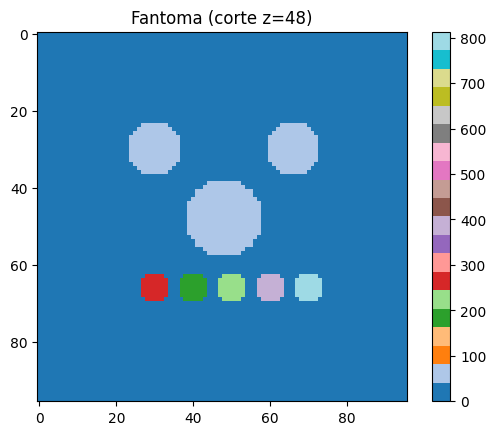

In [28]:
def make_phantom(shape=(96, 96, 96)):
    # Volumen de esferas concéntricas + algunas 'estructuras' internas con códigos ERC.
    zz, yy, xx = np.indices(shape)
    c = np.array(shape) // 2
    r = np.sqrt((zz - c[0])**2 + (yy - c[1])**2 + (xx - c[2])**2)
    lab = np.zeros(shape, dtype=int)            # 0   = fondo
    # lab[r < 50] = 41                            # 50  = ventrículo lateral (CSF)
    lab[r < 44] = 3                             # 3   = corteza (GM)
    lab[r < 38] = 2                             # 2   = SB cerebral (WM)
    lab[r < 10] = 50                            # 50  = ventrículo lateral (CSF)
    # 'núcleos' esféricos dentro de la SB
    def ball(center, rad, value):
        d = np.sqrt((zz - center[0])**2 + (yy - center[1])**2 + (xx - center[2])**2)
        lab[d < rad] = value
    ball((48, 30, 30), 7, 79)    # putamen
    ball((48, 30, 66), 7, 48)    # caudado

    # ball((48, 30, 30), 7, 2)    # putamen
    # ball((48, 30, 66), 7, 3)    # caudado

    ball((48, 66, 30), 4, 276)   # tálamo nivel 1 (casi WM)
    ball((48, 66, 40), 4, 201)   # tálamo nivel 2
    ball((48, 66, 50), 4, 218)   # tálamo nivel 3
    ball((48, 66, 60), 4, 400)   # tálamo nivel 4
    ball((48, 66, 70), 4, 813)   # tálamo nivel 5 (casi GM)
    ball((30, 48, 48), 6, 611)   # SB cerebelosa
    ball((66, 48, 48), 6, 344)   # hipocampo (radiatum)
    return lab

phantom = make_phantom()
labels = np.unique(phantom)
print('Etiquetas del fantoma:', labels)

plt.imshow(phantom[48], cmap='tab20', interpolation='nearest'); plt.title('Fantoma (corte z=48)'); plt.colorbar(); plt.show()

## 1. Funciones auxiliares

### `load_array_if_path(x)`
Si `x` es un `str` lo interpreta como ruta a un `.npy` y hace `np.load`; si no, hace `np.asarray(x)`. Así cualquier argumento de etiquetas puede ser lista, array o ruta.

In [29]:
print(load_array_if_path([0, 2, 3]))
print(load_array_if_path(np.array([0, 2, 3])))
print(load_array_if_path('data/output/labels.npy')[:10], '...')   # fichero .npy de la carpeta data/

[0 2 3]
[0 2 3]
[ 0  2  3  4  5  7  8 10 11 12] ...


### `convert_labelmap(labelmap, lut)`
Reetiqueta un volumen usando un diccionario `{etiqueta_original: nuevo_valor}`. Se usa sobre todo para pasar de los códigos del atlas (0, 2, 3, 50, 611, …) a **índices consecutivos** `0..N-1`, que es lo que permite indexar directamente los vectores `mus[...]` y `sigmas[...]`.

⚠️ Cualquier etiqueta que **no** esté en el `lut` se queda a `0`.

In [30]:
toy = np.array([[0, 2, 2], [3, 50, 999]])
print(convert_labelmap(toy, {0: 0, 2: 1, 3: 2, 50: 3}))   # 999 no está en el lut -> 0

[[0 1 1]
 [2 3 0]]


## 2. Crear el esquema

```python
ERCHierarchicalSampling(input_labels, randomize_less=True, std_noise=8 + np.random.randn(1), output_lut=None)
```

| argumento | qué hace |
|---|---|
| `input_labels` | lista / array / ruta `.npy` con **todas** las etiquetas que pueden aparecer en tus segmentaciones. Su orden define el índice `i` de cada etiqueta en `mus[i]`, `sigmas[i]`. |
| `randomize_less` | `True` (por defecto): los coeficientes de mezcla GM/WM son fijos y los incrementos aleatorios se reducen 5×. `False`: todo más aleatorio. |
| `std_noise` | ruido extra que se suma en cuadratura a todas las σ: $\sigma_k \leftarrow \sqrt{\sigma_k^2 + \text{std\_noise}^2}$. |
| `output_lut` | diccionario opcional `{etiqueta: clase_de_salida}` para agrupar etiquetas en el *target* de segmentación. |

Atributos que crea el constructor (clase base `SamplingScheme`):

In [31]:
scheme = ERCHierarchicalSampling(input_labels=labels)

print('input_labels      :', scheme.input_labels)
print('input_lut         :', scheme.input_lut)            # {etiqueta: índice}
print('n_input_labels    :', scheme.n_input_labels)
print('sampling_labels   :', scheme.sampling_labels, '->', scheme.dict_sampling_labels)
print('output_lut        :', scheme.output_lut)           # = input_lut si output_lut=None
print('n_output_labels   :', scheme.n_output_labels)
print('randomize_less    :', scheme.randomize_less, '| std_noise:', scheme.std_noise)

[GENERATIVE MODEL]: Remember that MU/STD BG,DURA,SKULL,SCALP=0 for all models (T1, T2, random, etc...)
input_labels      : [  0   2   3  48  50  79 201 218 276 344 400 611 813]
input_lut         : {0: 0, 2: 1, 3: 2, 48: 3, 50: 4, 79: 5, 201: 6, 218: 7, 276: 8, 344: 9, 400: 10, 611: 11, 813: 12}
n_input_labels    : 13
sampling_labels   : [0 1 2 3 4 5 6] -> {0: 'MU_GM', 1: 'MU_WM', 2: 'MU_CSF', 3: 'MU_BG', 4: 'MU_DURA', 5: 'MU_SKULL', 6: 'MU_SCALP'}
output_lut        : {0: 0, 2: 1, 3: 2, 48: 3, 50: 4, 79: 5, 201: 6, 218: 7, 276: 8, 344: 9, 400: 10, 611: 11, 813: 12}
n_output_labels   : 13
randomize_less    : True | std_noise: [8.55934362]


In [32]:
# # Cerebral white matter
# region_labels = [2, 7, 68, 120, 130, 199, 210, 445, 513, 514, 602, 100, 161, 208, 209]
# for lab in region_labels:
#     idxs = np.where(scheme.input_labels == lab)
#     idx = idxs[0]
#     print(idxs)
#     print(idx)


### Formas equivalentes de pasar las etiquetas

In [33]:
s_list = ERCHierarchicalSampling(list(labels))     # lista de Python
s_arr  = ERCHierarchicalSampling(labels)           # np.ndarray

# Desde un fichero .npy  -> ¡OJO! hay un bug: n_input_labels = len(<la ruta como string>)
s_path_bug = ERCHierarchicalSampling('data/output/labels.npy')
print('n_input_labels con ruta (BUG):', s_path_bug.n_input_labels, 'vs real:', len(s_path_bug.input_labels))

# Workaround: cargar tú el .npy antes
s_path_ok = ERCHierarchicalSampling(np.load('data/output/labels.npy'))
print('n_input_labels con np.load   :', s_path_ok.n_input_labels)

[GENERATIVE MODEL]: Remember that MU/STD BG,DURA,SKULL,SCALP=0 for all models (T1, T2, random, etc...)
[GENERATIVE MODEL]: Remember that MU/STD BG,DURA,SKULL,SCALP=0 for all models (T1, T2, random, etc...)
[GENERATIVE MODEL]: Remember that MU/STD BG,DURA,SKULL,SCALP=0 for all models (T1, T2, random, etc...)
n_input_labels con ruta (BUG): 22 vs real: 45
[GENERATIVE MODEL]: Remember that MU/STD BG,DURA,SKULL,SCALP=0 for all models (T1, T2, random, etc...)
n_input_labels con np.load   : 45


## 3. `compute_stats`: de 7 parámetros a N gaussianas

```python
mus, sigmas = scheme.compute_stats(high_level_mus, high_level_sigmas)
```

* `high_level_mus` y `high_level_sigmas` deben tener **exactamente 7 elementos**, en este orden:
  `[GM, WM, CSF, BG, DURA, SKULL, SCALP]`.
* BG, DURA, SKULL y SCALP se **sobrescriben a 0** dentro de la función (por eso el `print` de aviso del constructor). En la práctica sólo importan GM, WM y CSF.
* Devuelve dos vectores de longitud `n_input_labels`, alineados con `scheme.input_labels`.

Cómo se calcula cada grupo (resumen):

| grupo | μ |
|---|---|
| fondo (0) | 0 |
| SB cerebral | `MU_WM + small·ε` (cada etiqueta su propio ε) |
| SG cerebral | `MU_GM + small·ε` |
| ventrículos / plexo coroideo | `MU_CSF` (exacto) |
| SB / SG cerebelo | `MU_WM/GM + big·ε` (+ `medium·ε` por capa) |
| caudado, putamen, claustro | `MU_GM + medium·ε` (padre) → hijos `+ small·ε` |
| pericaudado, pálido, claustro temporal | mezcla `a·GM + (1-a)·WM` |
| hipocampo | capas WM-ish (mezcla) + 10 "tonos de GM" alrededor de un padre `mu_hippo_gm` |
| tálamo | 5 niveles de `a·WM+(1-a)·GM` con a = 0.85 … 0.15 |
| tronco (mesencéfalo) | 4 niveles análogos |
| hipotálamo | 5 niveles, sesgados hacia GM |
| amígdala | 3 niveles; núcleos cortical/medial/central forzados a compartir gaussiana |

Al final: $\sigma_k \leftarrow \sqrt{\sigma_k^2 + \text{std\_noise}^2}$.

**Las etiquetas que no pertenecen a ningún grupo quedan con μ=0** (sólo ruido) — muy importante si tus etiquetas no son del protocolo ERC.

In [34]:
np.random.seed(0)
#                      GM    WM   CSF  BG DURA SKULL SCALP
high_mus    = np.array([60., 110., 20., 0., 0., 0., 0.])   # tipo T1
high_sigmas = np.array([ 5.,   4.,  3., 0., 0., 0., 0.])

mus, sigmas = scheme.compute_stats(high_mus, high_sigmas)
for lab, m, s in zip(scheme.input_labels, mus, sigmas):
    print(f'etiqueta {lab:4d}:  mu = {float(m):7.2f}   sigma = {float(s):6.2f}')

etiqueta    0:  mu =    0.00   sigma =   8.56
etiqueta    2:  mu =  111.41   sigma =   9.52
etiqueta    3:  mu =   60.12   sigma =   9.99
etiqueta   48:  mu =   59.27   sigma =  10.49
etiqueta   50:  mu =   20.00   sigma =   9.07
etiqueta   79:  mu =   62.44   sigma =  10.00
etiqueta  201:  mu =   92.83   sigma =   9.38
etiqueta  218:  mu =   85.08   sigma =   9.60
etiqueta  276:  mu =  103.02   sigma =  10.05
etiqueta  344:  mu =   63.34   sigma =   9.54
etiqueta  400:  mu =   77.11   sigma =  10.15
etiqueta  611:  mu =  110.50   sigma =   9.25
etiqueta  813:  mu =   68.46   sigma =   9.75


## 4. Sintetizar una imagen

Pasos:
1. `scheme.convert_labelmap(lab)` → mapa de índices `0..N-1` (usa `input_lut` por defecto).
2. Indexar: `mus[idx]`, `sigmas[idx]`.
3. Añadir ruido gaussiano voxel a voxel.

In [35]:
mus = np.array([  0., 110.,  60.,  20.])
idx = np.array([0, 1, 1, 1])
print('mus[idx] =', mus[idx])

mus[idx] = [  0. 110. 110. 110.]


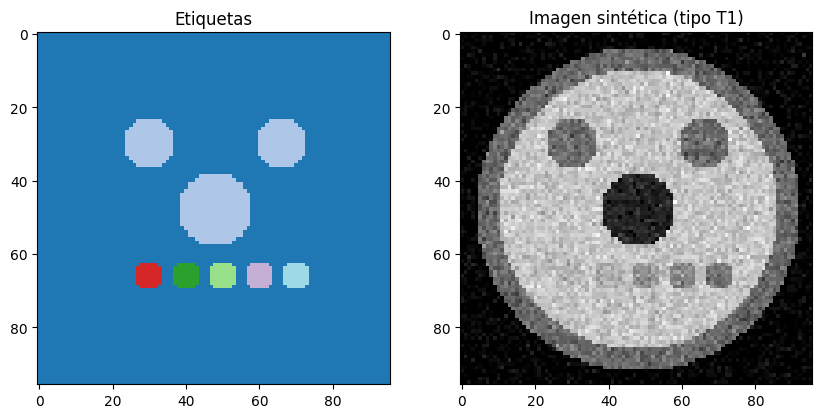

In [36]:
def synthesize(scheme, labelmap, high_mus, high_sigmas, clip=True):
    mus, sigmas = scheme.compute_stats(high_mus, high_sigmas)
    idx = scheme.convert_labelmap(labelmap) # convierte los labels grandes a indices
    img = mus[idx] + sigmas[idx] * np.random.randn(*idx.shape) # this creates an image becuase of numpy properties
    return np.clip(img, 0, None) if clip else img

np.random.seed(1)
img = synthesize(scheme, phantom, high_mus, high_sigmas)
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(phantom[48], cmap='tab20', interpolation='nearest'); ax[0].set_title('Etiquetas')
ax[1].imshow(img[48], cmap='gray'); ax[1].set_title('Imagen sintética (tipo T1)')
plt.show()

## 5. Distintos contrastes: T1, T2 y aleatorio

El mismo esquema genera cualquier contraste cambiando sólo los 3 valores relevantes (GM, WM, CSF). Para entrenar redes robustas al contraste (*domain randomization*) se muestrean aleatoriamente en cada iteración.

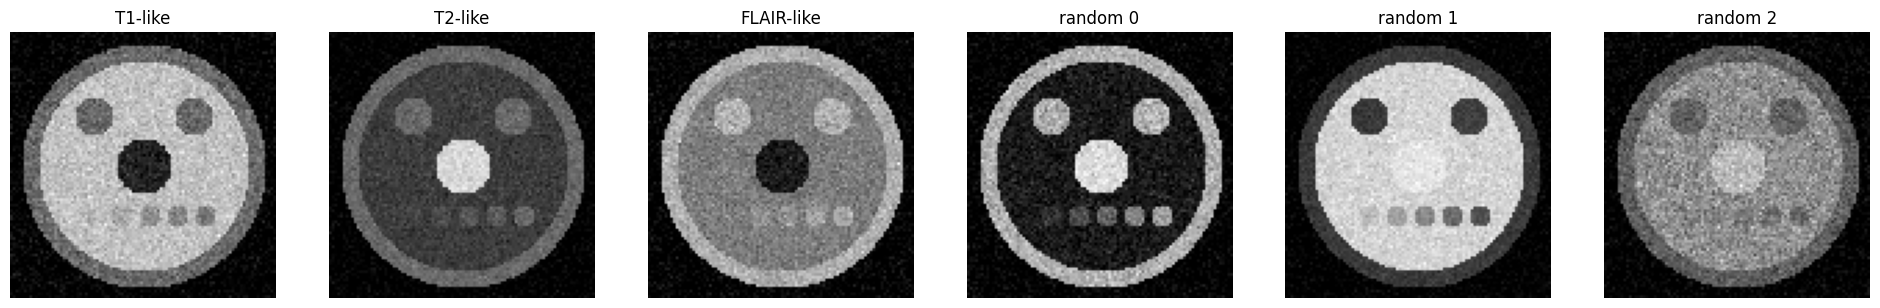

In [37]:
def zeros4(): return [0., 0., 0., 0.]

contrasts = {
    'T1-like':  (np.array([60., 110., 20.] + zeros4()), np.array([5., 4., 3.] + zeros4())),
    'T2-like':  (np.array([90.,  50., 180.] + zeros4()), np.array([5., 4., 6.] + zeros4())),
    'FLAIR-like': (np.array([100., 70., 15.] + zeros4()), np.array([5., 4., 3.] + zeros4())),
}
np.random.seed(2)
for i in range(3):   # 3 contrastes totalmente aleatorios
    contrasts[f'random {i}'] = (np.random.uniform(10, 240, 7), np.random.uniform(1, 15, 7))

fig, axes = plt.subplots(1, len(contrasts), figsize=(4 * len(contrasts), 4))
for ax, (name, (m, s)) in zip(axes, contrasts.items()):
    ax.imshow(synthesize(scheme, phantom, m, s)[48], cmap='gray'); ax.set_title(name); ax.axis('off')
plt.show()

### Bucle de generación (p. ej. dentro de un `Dataset` de PyTorch)

In [38]:
def random_contrast_generator(scheme, labelmap, n, mu_range=(10, 240), sigma_range=(1, 15)):
    for _ in range(n):
        hm = np.random.uniform(*mu_range, size=7)       # sólo se usan los 3 primeros
        hs = np.random.uniform(*sigma_range, size=7)
        image = synthesize(scheme, labelmap, hm, hs)
        target = scheme.convert_labelmap(labelmap, scheme.output_lut)   # segmentación objetivo
        yield image.astype(np.float32), target

for k, (x, y) in enumerate(random_contrast_generator(scheme, phantom, n=3)):
    print(k, x.shape, x.dtype, 'clases target:', np.unique(y))

0 (96, 96, 96) float32 clases target: [ 0  1  2  3  4  5  6  7  8  9 10 11 12]
1 (96, 96, 96) float32 clases target: [ 0  1  2  3  4  5  6  7  8  9 10 11 12]
2 (96, 96, 96) float32 clases target: [ 0  1  2  3  4  5  6  7  8  9 10 11 12]


## 6. `randomize_less` y `std_noise`

### `randomize_less`
Dentro de `compute_stats` hay cuatro magnitudes de perturbación (`small`, `medium`, `big`, `pinch_of_randomness`). Con `randomize_less=True` se dividen entre 5 y además los coeficientes de mezcla `a` son **fijos** (p. ej. pericaudado `a = 0.5`); con `False` los `a` se muestrean uniformemente en un rango. Después todo se multiplica por `factor = 2`.

| incremento | base | `randomize_less=True` | `False` |
|---|---|---|---|
| small μ / σ | 2 / 1 | 0.8 / 0.4 | 4 / 2 |
| medium μ / σ | 5 / 2 | 2 / 0.8 | 10 / 4 |
| big μ / σ | 7 / 3 | 2.8 / 1.2 | 14 / 6 |
| pinch | 1 | 0.4 | 2 |

Veámoslo empíricamente: misma entrada de alto nivel, 500 repeticiones, dispersión de μ por etiqueta.

[GENERATIVE MODEL]: Remember that MU/STD BG,DURA,SKULL,SCALP=0 for all models (T1, T2, random, etc...)


[GENERATIVE MODEL]: Remember that MU/STD BG,DURA,SKULL,SCALP=0 for all models (T1, T2, random, etc...)


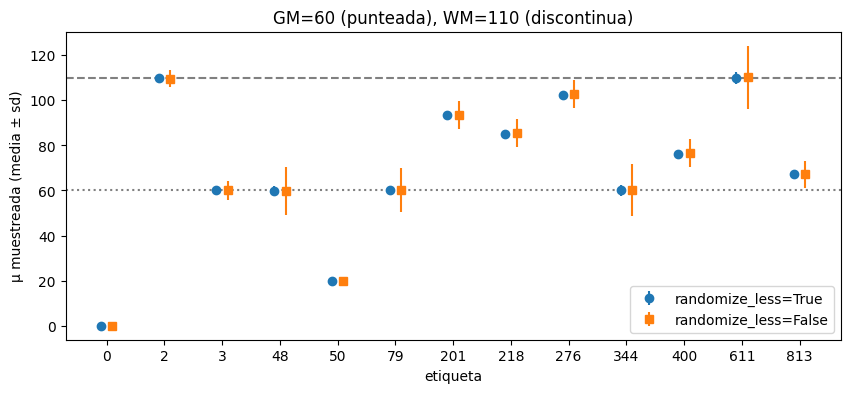

In [39]:
def mu_spread(randomize_less, n=500):
    s = ERCHierarchicalSampling(labels, randomize_less=randomize_less, std_noise=0.0)
    m = np.stack([s.compute_stats(high_mus, high_sigmas)[0] for _ in range(n)])
    return m.mean(0), m.std(0)

np.random.seed(3)
mean_T, std_T = mu_spread(True)
mean_F, std_F = mu_spread(False)
x = np.arange(len(labels))
plt.figure(figsize=(10, 4))
plt.errorbar(x - 0.1, mean_T, yerr=std_T, fmt='o', label='randomize_less=True')
plt.errorbar(x + 0.1, mean_F, yerr=std_F, fmt='s', label='randomize_less=False')
plt.xticks(x, labels); plt.xlabel('etiqueta'); plt.ylabel('μ muestreada (media ± sd)')
plt.axhline(high_mus[0], ls=':', c='gray'); plt.axhline(high_mus[1], ls='--', c='gray')
plt.legend(); plt.title('GM=60 (punteada), WM=110 (discontinua)'); plt.show()

### `std_noise`
Se añade en cuadratura a **todas** las σ, incluido el fondo (por eso el fondo nunca es negro puro).

⚠️ El valor por defecto `8 + np.random.randn(1)` se evalúa **una sola vez al importar el módulo**, así que todas las instancias comparten el mismo valor. Si quieres que varíe, pásalo explícitamente.

[GENERATIVE MODEL]: Remember that MU/STD BG,DURA,SKULL,SCALP=0 for all models (T1, T2, random, etc...)
[GENERATIVE MODEL]: Remember that MU/STD BG,DURA,SKULL,SCALP=0 for all models (T1, T2, random, etc...)
std_noise por defecto (igual en ambas): [8.55934362] [8.55934362]
[GENERATIVE MODEL]: Remember that MU/STD BG,DURA,SKULL,SCALP=0 for all models (T1, T2, random, etc...)
[GENERATIVE MODEL]: Remember that MU/STD BG,DURA,SKULL,SCALP=0 for all models (T1, T2, random, etc...)
[GENERATIVE MODEL]: Remember that MU/STD BG,DURA,SKULL,SCALP=0 for all models (T1, T2, random, etc...)
[GENERATIVE MODEL]: Remember that MU/STD BG,DURA,SKULL,SCALP=0 for all models (T1, T2, random, etc...)


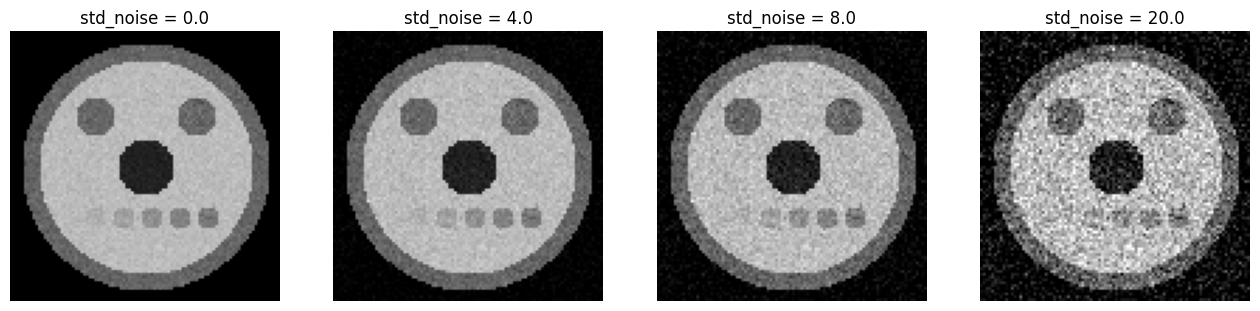

[GENERATIVE MODEL]: Remember that MU/STD BG,DURA,SKULL,SCALP=0 for all models (T1, T2, random, etc...)
std_noise aleatorio: 1.5858969034032089


In [40]:
a, b = ERCHierarchicalSampling(labels), ERCHierarchicalSampling(labels)
print('std_noise por defecto (igual en ambas):', a.std_noise, b.std_noise)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, sn in zip(axes, [0.0, 4.0, 8.0, 20.0]):
    s = ERCHierarchicalSampling(labels, std_noise=sn)
    np.random.seed(4)
    ax.imshow(synthesize(s, phantom, high_mus, high_sigmas)[48], cmap='gray', vmin=0, vmax=150)
    ax.set_title(f'std_noise = {sn}'); ax.axis('off')
plt.show()

# std_noise aleatorio por muestra:
s_rand = ERCHierarchicalSampling(labels, std_noise=np.random.uniform(0, 15))
print('std_noise aleatorio:', s_rand.std_noise)

## 7. Reproducibilidad

Todo usa el generador **global** `np.random` (no hay argumento `seed`/`rng`). Para reproducir resultados, fija `np.random.seed` justo antes de `compute_stats` (y de la generación de ruido).

In [41]:
np.random.seed(123); m1, s1 = scheme.compute_stats(high_mus, high_sigmas)
np.random.seed(123); m2, s2 = scheme.compute_stats(high_mus, high_sigmas)
m3, s3 = scheme.compute_stats(high_mus, high_sigmas)
print('misma semilla -> iguales:', np.allclose(m1, m2) and np.allclose(s1, s2))
print('sin semilla   -> iguales:', np.allclose(m1, m3))

misma semilla -> iguales: True
sin semilla   -> iguales: False


## 8. La jerarquía, en detalle: el tálamo

Los núcleos talámicos están clasificados (hoja de cálculo de Juri) en 5 niveles, de "casi SB" (1) a "casi SG" (5). Para cada nivel se calcula

$$\mu_\text{nivel} = a\,\mu_{WM} + (1-a)\,\mu_{GM} + \text{pinch}\cdot\varepsilon,\qquad a\in\{0.85, 0.675, 0.5, 0.325, 0.15\}$$

y cada núcleo de ese nivel recibe $\mu_\text{nivel} + \text{small}\cdot\varepsilon$. En el fantoma pusimos un núcleo de cada nivel (276, 201, 218, 400, 813):

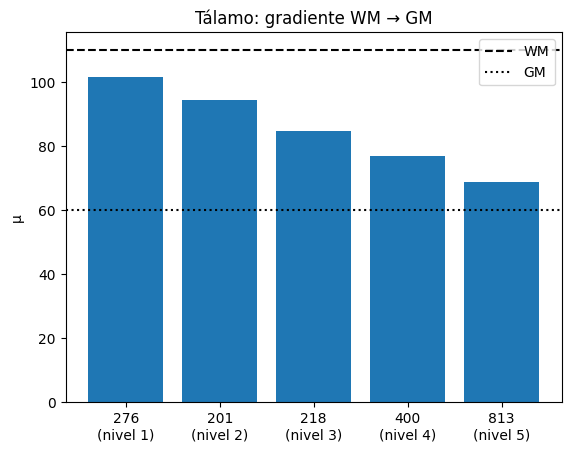

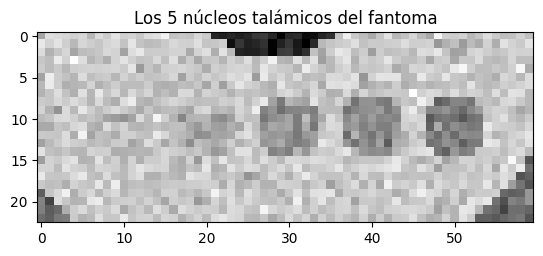

In [42]:
np.random.seed(5)
mus, sigmas = scheme.compute_stats(high_mus, high_sigmas)
th = [276, 201, 218, 400, 813]
vals = [float(mus[scheme.input_lut[l]]) for l in th]
plt.bar([f'{l}\n(nivel {i+1})' for i, l in enumerate(th)], vals)
plt.axhline(high_mus[1], c='k', ls='--', label='WM'); plt.axhline(high_mus[0], c='k', ls=':', label='GM')
plt.ylabel('μ'); plt.legend(); plt.title('Tálamo: gradiente WM → GM'); plt.show()

img = synthesize(scheme, phantom, high_mus, high_sigmas)
plt.imshow(img[48, 55:78, 20:80], cmap='gray'); plt.title('Los 5 núcleos talámicos del fantoma'); plt.show()

### Otras reglas jerárquicas

* **Mismo padre, hijos parecidos**: p. ej. caudado/accumbens (`48, 118, 393, 101`) comparten `mu_cau = MU_GM + medium·ε` y cada uno añade `small·ε`.
* **Gaussianas idénticas**: putamen `79` y putamen posteroventral `349` reciben exactamente la misma μ/σ; en hipocampo cada sub-lista (radiatum, pyramidale…) comparte μ/σ; en amígdala `249, 292, 300 ← 238`, `319 ← 279`, `278, 376 ← 277`.
* **Arreglos temporales**: la etiqueta `1` copia a `385` (núcleo rojo) y `500` copia a `575` (CA4).
* **Comprobación de solapes**: si una etiqueta aparece en dos grupos se lanza `ValueError('a label has already been assigned')`.

Comprobación con putamen y caudado:

In [43]:
s = ERCHierarchicalSampling([0, 2, 3, 79, 349, 48, 118, 393, 101])
np.random.seed(6)
m, sd = s.compute_stats(high_mus, high_sigmas)
L = s.input_lut
print('putamen 79 vs 349 (idénticos):', float(m[L[79]]), float(m[L[349]]))
print('caudado/accumbens (cercanos)  :', [round(float(m[L[k]]), 2) for k in [48, 118, 393, 101]])

[GENERATIVE MODEL]: Remember that MU/STD BG,DURA,SKULL,SCALP=0 for all models (T1, T2, random, etc...)
putamen 79 vs 349 (idénticos): 58.81624703772668 58.81624703772668
caudado/accumbens (cercanos)  : [62.28, 60.37, 59.72, 60.81]


## 9. `get_class_weights(subject_dict)`

Calcula pesos por clase para una pérdida ponderada (*median frequency balancing*):

$$w_k = \frac{\text{mediana}(f)}{f_k}$$

donde $f$ es una lista con la cantidad de voxeles para cada etiqueta, por lo tanto $\text{mediana}(f)$ es la madiana de numero de voxels por etiqueta y $f_k$ es el número medio de voxeles de la etiqueta $k$ por sujeto. Clases ausentes (`f_k = 0`) → peso 0.

Espera un **diccionario de sujetos** donde cada sujeto tiene un atributo `.labelmap` que es una imagen nibabel (usa `.dataobj`). Aquí lo simulamos con `SimpleNamespace`:

In [ ]:
import nibabel as nib

subjects = {
    'sub-01': SimpleNamespace(labelmap=nib.Nifti1Image(phantom.astype(np.int32), np.eye(4))),
    'sub-02': SimpleNamespace(labelmap=nib.Nifti1Image(make_phantom((80, 80, 80)).astype(np.int32), np.eye(4))),
}
w = scheme.get_class_weights(subjects)
for lab, wk in zip(scheme.input_labels, w):
    print(f'etiqueta {lab:4d}: peso {wk:8.3f}')

etiqueta    0: peso    0.003
etiqueta    2: peso    0.004
etiqueta    3: peso    0.007
etiqueta   48: peso    0.656
etiqueta   50: peso    0.217
etiqueta   79: peso    0.656
etiqueta  201: peso    3.566
etiqueta  218: peso    3.566
etiqueta  276: peso    3.566
etiqueta  344: peso    1.000
etiqueta  400: peso    3.566
etiqueta  611: peso    1.000
etiqueta  813: peso    3.566


## 10. `output_lut`: agrupar etiquetas para el *target*

`output_lut` **no afecta a la síntesis** (`compute_stats` siempre trabaja con `input_labels`); sólo sirve para convertir la segmentación objetivo, p. ej. para entrenar una red con menos clases.

[GENERATIVE MODEL]: Remember that MU/STD BG,DURA,SKULL,SCALP=0 for all models (T1, T2, random, etc...)
output_labels  : [0 1 2 3 4] | n_output_labels: 5


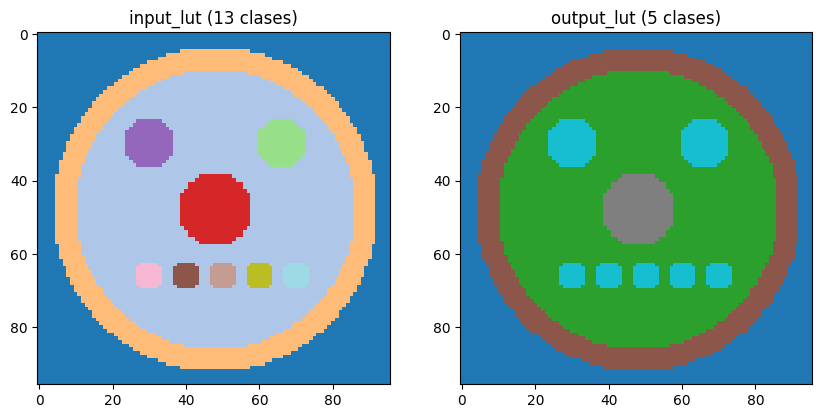

In [45]:
# Agrupamos en 5 clases: 0 fondo, 1 WM, 2 GM cortical, 3 CSF, 4 subcortical
output_lut = {0: 0, 2: 1, 611: 1, 3: 2, 50: 3}
for l in labels:
    output_lut.setdefault(int(l), 4)

s_out = ERCHierarchicalSampling(labels, output_lut=output_lut)
print('output_labels  :', s_out.output_labels, '| n_output_labels:', s_out.n_output_labels)

target_full    = s_out.convert_labelmap(phantom)                      # 0..N-1 (input_lut)
target_grouped = s_out.convert_labelmap(phantom, s_out.output_lut)    # 0..4

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(target_full[48], cmap='tab20', interpolation='nearest'); ax[0].set_title(f'input_lut ({s_out.n_input_labels} clases)')
ax[1].imshow(target_grouped[48], cmap='tab10', interpolation='nearest'); ax[1].set_title(f'output_lut ({s_out.n_output_labels} clases)')
plt.show()

## 11. Crear tu propio esquema heredando de `SamplingScheme`

La clase base aporta las LUTs, `convert_labelmap` y `get_class_weights`. Sólo hay que implementar `compute_stats`. (La versión base está "decorada" con `@NotImplementedError`, así que llamarla directamente da un `TypeError`, no un `NotImplementedError`.)

In [24]:
try:
    SamplingScheme([0, 1], sampling_labels=[0], output_lut=None).compute_stats(None, None)
except Exception as e:
    print(type(e).__name__, '->', e)

TypeError -> 'NotImplementedError' object is not callable


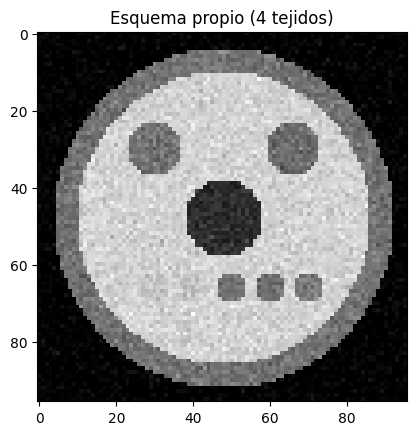

In [25]:
class SimpleTissueSampling(SamplingScheme):
    # Esquema mínimo: cada etiqueta se asigna a un tejido y hereda su gaussiana + una pequeña perturbación.
    TISSUES = ['GM', 'WM', 'CSF', 'BG']

    def __init__(self, input_labels, tissue_map, jitter=3.0, std_noise=5.0, output_lut=None):
        self.tissue_map = tissue_map          # {etiqueta: 'GM'|'WM'|'CSF'|'BG'}
        self.jitter, self.std_noise = jitter, std_noise
        super().__init__(input_labels, sampling_labels=list(range(len(self.TISSUES))), output_lut=output_lut)

    def compute_stats(self, high_level_mus, high_level_sigmas, n_channels=1):
        mus = np.zeros(self.n_input_labels); sig = np.zeros(self.n_input_labels)
        for lab, i in self.input_lut.items():
            t = self.TISSUES.index(self.tissue_map.get(lab, 'BG'))
            mus[i] = high_level_mus[t] + (self.jitter * np.random.randn() if t != 3 else 0)
            sig[i] = high_level_sigmas[t]
        return mus, np.sqrt(sig**2 + self.std_noise**2)

tissue_map = {2: 'WM', 611: 'WM', 3: 'GM', 79: 'GM', 48: 'GM', 344: 'GM', 50: 'CSF',
              276: 'WM', 201: 'WM', 218: 'GM', 400: 'GM', 813: 'GM'}
simple = SimpleTissueSampling(labels, tissue_map)
plt.imshow(synthesize(simple, phantom, [60, 110, 20, 0], [5, 4, 3, 0])[48], cmap='gray')
plt.title('Esquema propio (4 tejidos)'); plt.show()

## 12. Con una segmentación real

Ejemplo con la segmentación de SuperSynth usada en `test_sampling.ipynb`. **Atención:** esa segmentación usa códigos **FreeSurfer** (41 = SB derecha, 42 = corteza derecha, 10 = tálamo, 17 = hipocampo…), mientras que `ERCHierarchicalSampling` espera códigos **ERC/NextBrain**. Consecuencias:

* Sólo coinciden por casualidad algunas etiquetas (2, 3, 7, 49, 50), y además con significado distinto (en FS 49 es tálamo derecho y 50 caudado derecho; aquí son pericaudado y ventrículo).
* El resto queda con μ = 0 → el hemisferio derecho y la mayoría de estructuras aparecen negras.

Para FreeSurfer usa `sampling_scheme_v2.GenericHierarchicalSampling(labels, config='freesurfer')`.

[GENERATIVE MODEL]: Remember that MU/STD BG,DURA,SKULL,SCALP=0 for all models (T1, T2, random, etc...)
Etiquetas sin asignar (mu=0): [  4   5   8  10  11  12  13  14  15  16  17  18  24  26  41  42  43  44
  46  47  51  52  53  54  58  77  85 819 820 821 822 843 844 865 866 869
 870 902 915]


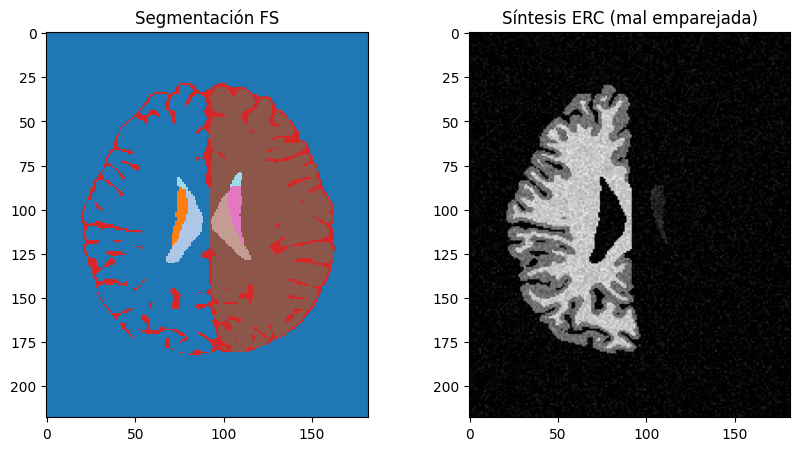

In [26]:
import os
seg_path = '/home/agustin/phd/fast_nextbrain2/data/test/outputs/mrxfields/T1W/7T/001_GX/SuperSynth/segmentation.nii.gz'

if os.path.exists(seg_path):
    seg = nib.load(seg_path)
    lab = np.asarray(seg.dataobj).astype(int)
    real_labels = np.unique(lab)
    s_real = ERCHierarchicalSampling(real_labels)
    np.random.seed(7)
    mus_r, _ = s_real.compute_stats(high_mus, high_sigmas)
    print('Etiquetas sin asignar (mu=0):', real_labels[(mus_r == 0) & (real_labels != 0)])
    img_r = synthesize(s_real, lab, high_mus, high_sigmas)
    z = lab.shape[2] // 2
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(np.rot90(lab[:, :, z]), cmap='tab20', interpolation='nearest'); ax[0].set_title('Segmentación FS')
    ax[1].imshow(np.rot90(img_r[:, :, z]), cmap='gray'); ax[1].set_title('Síntesis ERC (mal emparejada)')
    plt.show()
    # Para guardar: nib.save(nib.Nifti1Image(img_r.astype(np.float32), seg.affine), 'data/output/synth_erc.nii.gz')
else:
    print('No se encuentra', seg_path)

## 13. Problemas conocidos / cosas a tener en cuenta

| # | Problema | Dónde | Consecuencia | Solución rápida |
|---|---|---|---|---|
| 1 | `n_input_labels = len(input_labels)` usa el argumento crudo | `SamplingScheme.__init__` | Si pasas una **ruta**, cuenta caracteres del string | Pasa `np.load(ruta)` |
| 2 | Lo mismo con `n_sampling_labels` | idem | idem | — |
| 3 | `std_noise=8 + np.random.randn(1)` como valor por defecto | `ERCHierarchicalSampling.__init__` | Se evalúa una vez al importar; todas las instancias comparten valor | Pásalo explícitamente |
| 4 | Etiquetas no listadas reciben μ=0 sin aviso | `compute_stats` | Estructuras negras (ver sección 12) | Comprueba `mus == 0` |
| 5 | `high_level_*` deben tener 7 valores aunque 4 se ignoren | `compute_stats` | `ValueError: not enough values to unpack` | Rellena con ceros |
| 6 | Arreglo `1 ← 385` / `500 ← 575` falla si existe la 1 (o 500) pero no la 385 (o 575) | final de `compute_stats` | `ValueError: shape mismatch` | Incluye 385/575 en `input_labels` |
| 7 | `convert_labelmap` manda etiquetas desconocidas a 0 | función | Se sintetizan como la etiqueta en el índice 0 (fondo) | Asegura que `input_labels` cubre todas |
| 8 | `@NotImplementedError` como decorador | clase base | `TypeError` en vez de `NotImplementedError` | Usar `raise NotImplementedError` |
| 9 | Las μ pueden salir negativas (con contrastes bajos y `randomize_less=False`) | `compute_stats` | Valores negativos en la imagen | `np.clip(img, 0, None)` |
| 10 | `n_channels` y `output_lut` no se usan en la síntesis | — | Sólo un canal | — |
| 11 | Usa `np.random` global | todo | Difícil de reproducir en multiproceso (DataLoader workers) | `np.random.seed` por worker |

In [27]:
# Demostración del punto 6
try:
    ERCHierarchicalSampling([0, 1, 2, 3]).compute_stats(high_mus, high_sigmas)
except ValueError as e:
    print('ValueError:', e)
print('Con 385 incluida funciona:', ERCHierarchicalSampling([0, 1, 2, 3, 385]).compute_stats(high_mus, high_sigmas)[0].shape)

[GENERATIVE MODEL]: Remember that MU/STD BG,DURA,SKULL,SCALP=0 for all models (T1, T2, random, etc...)
ValueError: shape mismatch: value array of shape (0,) could not be broadcast to indexing result of shape (1,)
[GENERATIVE MODEL]: Remember that MU/STD BG,DURA,SKULL,SCALP=0 for all models (T1, T2, random, etc...)
Con 385 incluida funciona: (5,)


In [ ]:
Por hacer:
crear sistema jerarquico de etiquetas (planificar bien la media y std de los padres) 
masking de ramas
generalizacion de codigo (ya hecho con la otra version)
